In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Machine Learning Libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
# Performance Evaluation Metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

In [ ]:
cancer = load_breast_cancer()

df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['Target'] = cancer.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
print("Dataset Shape:", df.shape)
print("\nFeature Names:")
print(df.columns)
print("\nTarget Classes:")
print(cancer.target_names)
print("\nTarget Distribution:")
print(df['Target'].value_counts())

Dataset Shape: (569, 31)

Feature Names:
Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'Target'],
      dtype='object')

Target Classes:
['malignant' 'benign']

Target Distribution:
Target
1    357
0    212
Name: count, dtype: int64


In [ ]:
X=df.drop('Target', axis=1)
y=df['Target']
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Matrix Shape: (569, 30)
Target Shape: (569,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training Set Shape:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

Training Set Shape:
X_train: (455, 30)
y_train: (455,)


In [ ]:
model=LogisticRegression()
model.fit(X_train, y_train)
print("Model Training Complete")

Model Training Complete


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
y_pred=model.predict(X_test)
print("Prediction Complete")
print(y_pred[:20])

Prediction Complete
[1 0 0 1 1 0 0 0 1 1 1 0 1 0 1 0 1 1 1 0]


In [ ]:
accuracy=accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Accuracy: 0.956140350877193


In [ ]:
cm=confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[39  4]
 [ 1 70]]


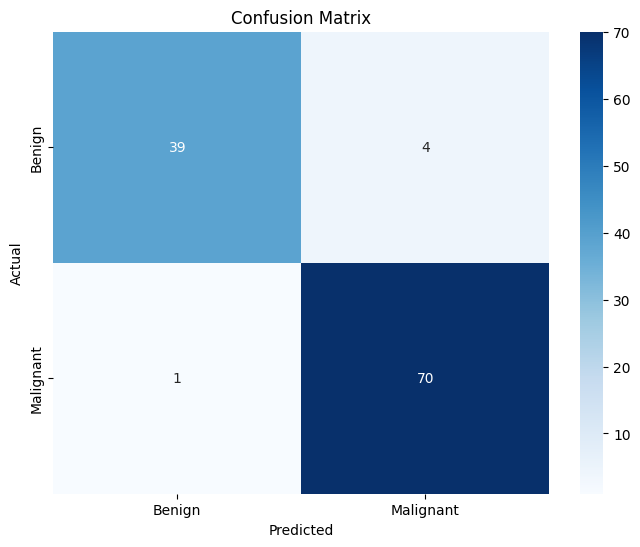

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
precision=precision_score(y_test, y_pred)
recall=recall_score(y_test, y_pred)
f1=f1_score(y_test, y_pred)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.9459459459459459
Recall: 0.9859154929577465
F1 Score: 0.9655172413793104


In [ ]:
report=classification_report(y_test, y_pred)
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        43
           1       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
y_pred_prob=model.predict_proba(X_test)[:, 1]
print("Predicted Probabilities:")
print(y_pred_prob[:20])

Predicted Probabilities:
[8.51745717e-01 6.94561794e-10 1.37351305e-03 9.95656660e-01
 9.99077616e-01 1.61405498e-10 1.77992542e-13 1.07030410e-02
 9.98782122e-01 9.86668629e-01 9.41154909e-01 3.68846352e-04
 9.90337441e-01 2.11659896e-01 9.98026656e-01 7.94763225e-04
 9.97462571e-01 9.99460948e-01 9.98042120e-01 3.10100583e-08]


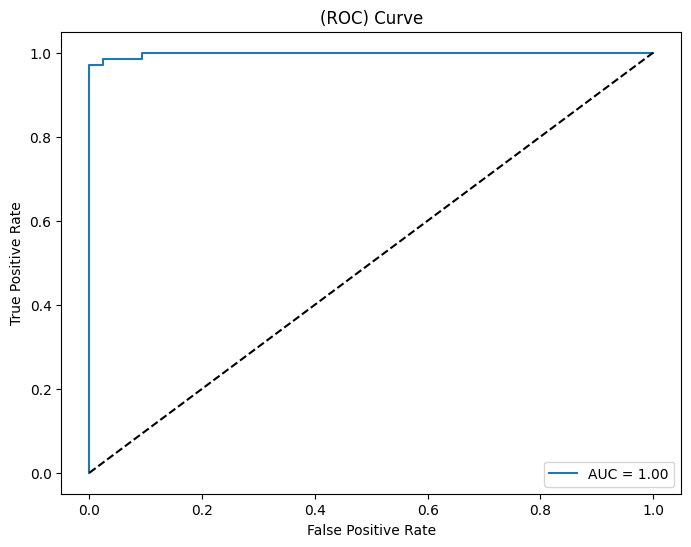

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label= f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('(ROC) Curve')
plt.legend(loc='lower right')
plt.show()

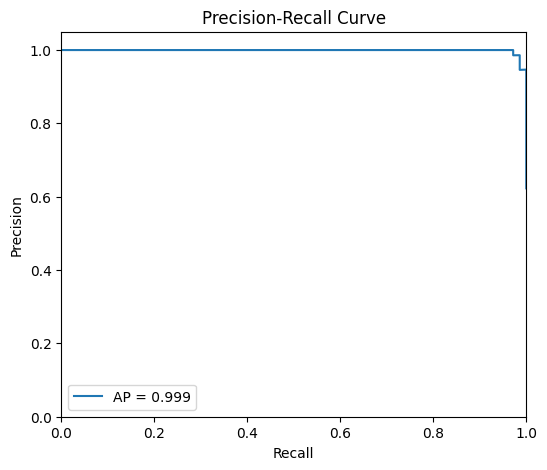

Average Precision (AP) = 0.9991


In [ ]:
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_test,y_pred_prob)
# Calculate Average Precision
ap_score = average_precision_score(y_test, y_pred_prob)
plt.figure(figsize=(6,5))
plt.plot(
recall_curve,
precision_curve,
label=f'AP = {ap_score:.3f}'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.show()
print("Average Precision (AP) =", round(ap_score, 4))

In [ ]:
print("========== ROC & Precision-Recall Evaluation ==========")
print("AUC :", round(roc_auc, 4))
print("AP :", round(ap_score, 4))

========== ROC & Precision-Recall Evaluation ==========
AUC : 0.9984
AP : 0.9991
